# Annexure B: Full analysis code
## A Comparative Analysis of Logistic Regression and XGBoost for Credit Risk Assessment Using SHAP-Based Explainability in a South African Banking Contextk (Statlog German Credit)
**Student:** Tashvir Singh (ST10491030) · **Module:** RPDA8412 · **Supervisor:** Dr Deborah Oluwadele

This notebook contains the complete code for the study. It follows the nine-stage workflow in Table 2 of the report, and every table and figure in Section 4 is produced here.

| Stage | Section | Report output |
|---|---|---|
| 1. Data review and EDA | 1 | Section 4.1, Figure 2 |
| 2. Target definition | 2 | Section 3.5.2 |
| 3. Preprocessing | 3 | Section 3.5.3 |
| 4. Stratified 70/30 split | 4 | Section 4.1 |
| 5. Model training + 5-fold CV | 5 | Annexure B (CV output) |
| 6. Performance evaluation | 6 | Tables 4–5, Figures 3 and 5 |
| 7. Cost-sensitive threshold | 7 | Figure 6 |
| 8. SHAP explanations | 8 | Figure 7 |
| 9. SHAP stability (10 seeds) | 9 | Tables 6–7, Figures 4 and 8, Section 4.7 |

**How to run:** in Google Colab, choose Runtime → Run all (about 2–3 minutes). Figures are saved as PNG files in the working folder.

## 0. Setup

In [1]:
import sys, subprocess
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'shap', 'xgboost', 'ucimlrepo'], check=False)

import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import sklearn, xgboost, shap, scipy
from itertools import combinations
from scipy.stats import spearmanr, ks_2samp
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

SEED = 42                      # seed for the primary split and models
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
for lib in (np, pd, sklearn, xgboost, shap, scipy):
    print(f'{lib.__name__:<12}{lib.__version__}')
print('python      ', sys.version.split()[0])

numpy       2.4.6
pandas      2.2.3
sklearn     1.6.1
xgboost     3.4.1
shap        0.54.1
scipy       1.16.3
python       3.13.18


## 1. Data review and exploratory analysis (Stage 1)
The Statlog (German Credit) dataset (Hofmann, 1994) is loaded directly from the UCI Machine Learning Repository with `ucimlrepo`. The **original** categorical-code version is used (20 attributes: 7 numerical, 13 categorical). If the UCI service is unavailable, an identical copy of `german.data` is loaded from a GitHub mirror instead.

In [2]:
COLS = [f'Attribute{i}' for i in range(1, 21)]
try:
    from ucimlrepo import fetch_ucirepo
    gc = fetch_ucirepo(id=144)
    X = gc.data.features.copy(); y_raw = gc.data.targets.iloc[:, 0].copy()
    source = 'UCI Machine Learning Repository (ucimlrepo, id=144)'
except Exception as e:
    url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/german.csv'   # identical copy of german.data
    raw = pd.read_csv(url, header=None, names=COLS + ['class'])
    X, y_raw = raw[COLS].copy(), raw['class'].copy()
    source = f'GitHub mirror of german.data ({url}); UCI unavailable: {type(e).__name__}'
print('Source:', source)

# Readable names for the 20 UCI attributes (used in tables and SHAP aggregation)
NAMES = {'Attribute1': 'checking_account', 'Attribute2': 'duration_months', 'Attribute3': 'credit_history',
         'Attribute4': 'purpose', 'Attribute5': 'credit_amount', 'Attribute6': 'savings',
         'Attribute7': 'employment_since', 'Attribute8': 'instalment_rate', 'Attribute9': 'personal_status_sex',
         'Attribute10': 'other_debtors', 'Attribute11': 'residence_since', 'Attribute12': 'property',
         'Attribute13': 'age_years', 'Attribute14': 'other_instalments', 'Attribute15': 'housing',
         'Attribute16': 'existing_credits', 'Attribute17': 'job', 'Attribute18': 'people_liable',
         'Attribute19': 'telephone', 'Attribute20': 'foreign_worker'}

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
print(f'Shape: {X.shape} | numerical: {len(num_cols)} | categorical: {len(cat_cols)}')
print('Numerical  :', [NAMES[c] for c in num_cols])
print('Categorical:', [NAMES[c] for c in cat_cols])
print('Missing values:', int(X.isna().sum().sum()), '| Duplicate rows:', int(pd.concat([X, y_raw], axis=1).duplicated().sum()))
print('Raw target counts (1 = good, 2 = bad):', y_raw.value_counts().sort_index().to_dict())
X.rename(columns=NAMES).head()

Source: UCI Machine Learning Repository (ucimlrepo, id=144)
Shape: (1000, 20) | numerical: 7 | categorical: 13
Numerical  : ['duration_months', 'credit_amount', 'instalment_rate', 'residence_since', 'age_years', 'existing_credits', 'people_liable']
Categorical: ['checking_account', 'credit_history', 'purpose', 'savings', 'employment_since', 'personal_status_sex', 'other_debtors', 'property', 'other_instalments', 'housing', 'job', 'telephone', 'foreign_worker']
Missing values: 0 | Duplicate rows: 0
Raw target counts (1 = good, 2 = bad): {1: 700, 2: 300}


,checking_account,duration_months,credit_history,purpose,credit_amount,savings,employment_since,instalment_rate,personal_status_sex,other_debtors,residence_since,property,age_years,other_instalments,housing,existing_credits,job,people_liable,telephone,foreign_worker
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201


In [3]:
Xn = X.rename(columns=NAMES)
print(Xn.describe().T.round(2))

                   count     mean      std    min     25%     50%      75%  \
duration_months   1000.0    20.90    12.06    4.0    12.0    18.0    24.00   
credit_amount     1000.0  3271.26  2822.74  250.0  1365.5  2319.5  3972.25   
instalment_rate   1000.0     2.97     1.12    1.0     2.0     3.0     4.00   
residence_since   1000.0     2.84     1.10    1.0     2.0     3.0     4.00   
age_years         1000.0    35.55    11.38   19.0    27.0    33.0    42.00   
existing_credits  1000.0     1.41     0.58    1.0     1.0     1.0     2.00   
people_liable     1000.0     1.16     0.36    1.0     1.0     1.0     1.00   

                      max  
duration_months      72.0  
credit_amount     18424.0  
instalment_rate       4.0  
residence_since       4.0  
age_years            75.0  
existing_credits      4.0  
people_liable         2.0  


### Figure 2: distribution of loan duration, credit amount and age by class

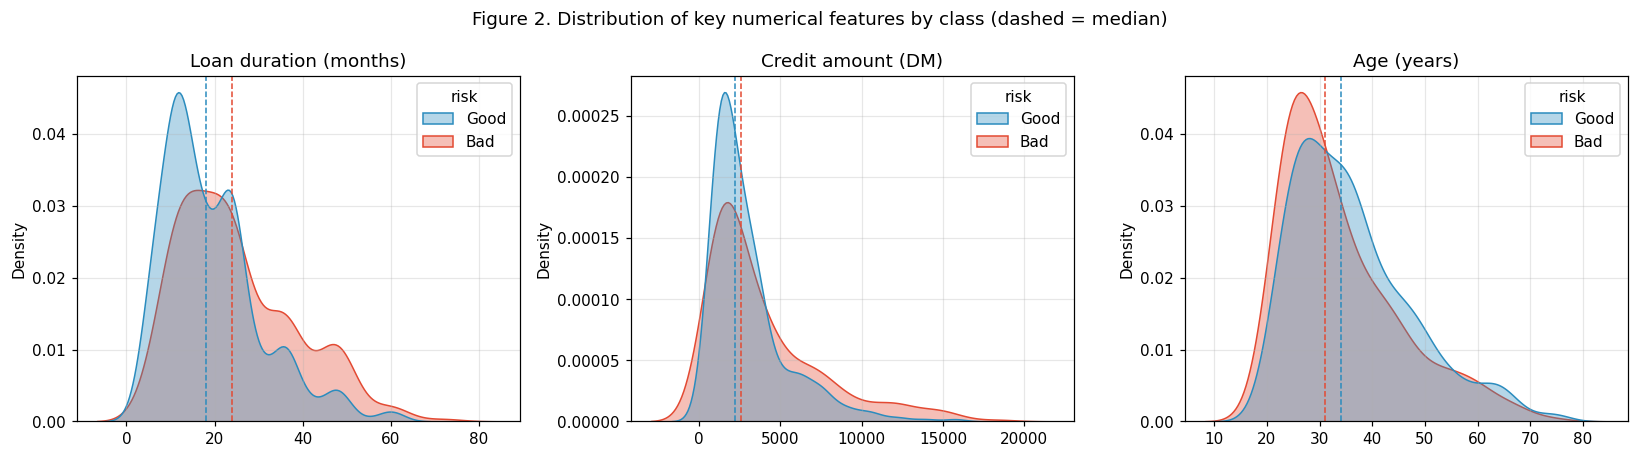

      duration_months  credit_amount  age_years
risk                                           
Bad              24.0         2574.5       31.0
Good             18.0         2244.0       34.0


In [4]:
plot_df = Xn[['duration_months', 'credit_amount', 'age_years']].assign(
    risk=np.where(y_raw == 2, 'Bad', 'Good'))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
titles = {'duration_months': 'Loan duration (months)', 'credit_amount': 'Credit amount (DM)', 'age_years': 'Age (years)'}
for ax, col in zip(axes, titles):
    sns.kdeplot(data=plot_df, x=col, hue='risk', common_norm=False, fill=True, alpha=0.35,
                palette={'Good': '#2b8cbe', 'Bad': '#e34a33'}, ax=ax)
    ax.set_title(titles[col]); ax.set_xlabel('')
    for r, c in (('Good', '#2b8cbe'), ('Bad', '#e34a33')):
        ax.axvline(plot_df.loc[plot_df.risk == r, col].median(), color=c, ls='--', lw=1)
fig.suptitle('Figure 2. Distribution of key numerical features by class (dashed = median)')
plt.tight_layout(); plt.savefig('fig2_distributions.png', dpi=200, bbox_inches='tight'); plt.show()
print(plot_df.groupby('risk').median().round(1))

## 2. Target definition (Stage 2)
In the raw data 1 = good and 2 = bad. The target is recoded so that **1 = bad (default)**, which makes the costly minority event the positive class.

In [5]:
y = (y_raw == 2).astype(int).rename('bad')
print(y.value_counts().rename({0: 'good (0)', 1: 'bad (1)'}).to_string())
print(f'Default rate: {y.mean():.1%}')

bad
good (0)    700
bad (1)     300
Default rate: 30.0%


## 3. Preprocessing (Stage 3) and 4. Stratified 70/30 split (Stage 4)
One `ColumnTransformer` standardises the 7 numerical features and one-hot encodes the 13 categorical features. It is fitted on the **training data only**, and both models receive exactly the same transformed inputs.

In [6]:
def make_preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)])

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
pre = make_preprocessor()
Xtr = pre.fit_transform(X_tr); Xte = pre.transform(X_te)
feat_names = pre.get_feature_names_out()
print(f'Train: {len(y_tr)} records ({y_tr.sum()} bad, {(y_tr == 0).sum()} good)')
print(f'Test : {len(y_te)} records ({y_te.sum()} bad, {(y_te == 0).sum()} good)')
print(f'Encoded feature matrix: {Xtr.shape[1]} columns')

Train: 700 records (210 bad, 490 good)
Test : 300 records (90 bad, 210 good)
Encoded feature matrix: 61 columns


## 5. Model training and 5-fold stratified cross-validation (Stage 5)
- **Logistic Regression:** L2 regularisation, `class_weight='balanced'`.
- **XGBoost:** conservative configuration for 700 training records (depth 3, learning rate 0.05, 300 trees, 0.8 row and column subsampling) and `scale_pos_weight` = good/bad ratio in the training data.

Cross-validation runs on the training data only. Preprocessing sits inside the pipeline, so it is refitted in every fold and nothing leaks between folds.

In [7]:
spw = (y_tr == 0).sum() / (y_tr == 1).sum()
def make_lr():
    return LogisticRegression(penalty='l2', class_weight='balanced', max_iter=2000)
def make_xgb(seed, spw):
    return XGBClassifier(max_depth=3, learning_rate=0.05, n_estimators=300, subsample=0.8, colsample_bytree=0.8,
                         scale_pos_weight=spw, eval_metric='logloss', random_state=seed)
print(f'scale_pos_weight = {spw:.3f}')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = {}
for name, est in [('Logistic Regression', make_lr()), ('XGBoost', make_xgb(SEED, spw))]:
    res = cross_validate(Pipeline([('pre', make_preprocessor()), ('model', est)]), X_tr, y_tr, cv=cv,
                         scoring=['roc_auc', 'accuracy', 'recall', 'precision', 'f1'])
    cv_rows[name] = {m: f"{res['test_' + m].mean():.3f} ± {res['test_' + m].std():.3f}"
                     for m in ['roc_auc', 'accuracy', 'recall', 'precision', 'f1']}
    print(f'{name:<20} fold ROC-AUC:', np.round(res['test_roc_auc'], 3))
print('\n5-fold CV on the training set (mean ± SD; recall/precision/F1 = bad class):')
pd.DataFrame(cv_rows).T

scale_pos_weight = 2.333
Logistic Regression  fold ROC-AUC: [0.754 0.791 0.756 0.716 0.783]
XGBoost              fold ROC-AUC: [0.807 0.788 0.744 0.718 0.788]

5-fold CV on the training set (mean ± SD; recall/precision/F1 = bad class):


,roc_auc,accuracy,recall,precision,f1
Logistic Regression,0.760 ± 0.026,0.706 ± 0.011,0.705 ± 0.032,0.508 ± 0.014,0.590 ± 0.007
XGBoost,0.769 ± 0.033,0.731 ± 0.033,0.614 ± 0.046,0.550 ± 0.050,0.579 ± 0.040


In [8]:
lr = make_lr().fit(Xtr, y_tr)
xgb = make_xgb(SEED, spw).fit(Xtr, y_tr)
p_lr = lr.predict_proba(Xte)[:, 1]; p_xgb = xgb.predict_proba(Xte)[:, 1]
print('Both models fitted on the 700 training records.')

Both models fitted on the 700 training records.


## 6. Performance evaluation on the held-out test set (Stage 6)
Ranking measures (ROC-AUC, Gini = 2·AUC − 1, KS) plus accuracy and bad-class precision, recall and F1 at the 0.50 threshold.

In [9]:
def ks_stat(y_true, p):
    return ks_2samp(p[y_true == 1], p[y_true == 0]).statistic

def evaluate(y_true, p, thr=0.5):
    yhat = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y_true, yhat).ravel(); auc = roc_auc_score(y_true, p)
    return {'Accuracy': accuracy_score(y_true, yhat), 'ROC-AUC': auc, 'Gini': 2 * auc - 1, 'KS': ks_stat(np.asarray(y_true), p),
            'Recall (bad)': recall_score(y_true, yhat), 'Precision (bad)': precision_score(y_true, yhat),
            'F1 (bad)': f1_score(y_true, yhat), 'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn, 'Expected cost (5·FN+FP)': 5 * fn + fp}

perf = pd.DataFrame({'Logistic Regression': evaluate(y_te, p_lr), 'XGBoost': evaluate(y_te, p_xgb)}).T
perf.loc['Difference (LR − XGB)'] = perf.loc['Logistic Regression'] - perf.loc['XGBoost']
print('Table 4 / Table 5: held-out test set (n = 300)')
perf.round(3)

Table 4 / Table 5: held-out test set (n = 300)


,Accuracy,ROC-AUC,Gini,KS,Recall (bad),Precision (bad),F1 (bad),TP,FN,FP,TN,Expected cost (5·FN+FP)
Logistic Regression,0.730,0.804,0.607,0.502,0.767,0.535,0.630,69.0,21.0,60.0,150.0,165.0
XGBoost,0.753,0.801,0.603,0.476,0.644,0.580,0.611,58.0,32.0,42.0,168.0,202.0
Difference (LR − XGB),-0.023,0.002,0.005,0.025,0.122,-0.045,0.020,11.0,-11.0,18.0,-18.0,-37.0


In [10]:
for name, p in [('Logistic Regression', p_lr), ('XGBoost', p_xgb)]:
    print(f'===== {name} =====')
    print(classification_report(y_te, (p >= 0.5).astype(int), target_names=['good (0)', 'bad (1)'], digits=3))

===== Logistic Regression =====
              precision    recall  f1-score   support

    good (0)      0.877     0.714     0.787       210
     bad (1)      0.535     0.767     0.630        90

    accuracy                          0.730       300
   macro avg      0.706     0.740     0.709       300
weighted avg      0.775     0.730     0.740       300

===== XGBoost =====
              precision    recall  f1-score   support

    good (0)      0.840     0.800     0.820       210
     bad (1)      0.580     0.644     0.611        90

    accuracy                          0.753       300
   macro avg      0.710     0.722     0.715       300
weighted avg      0.762     0.753     0.757       300



### Figure 3: ROC curves

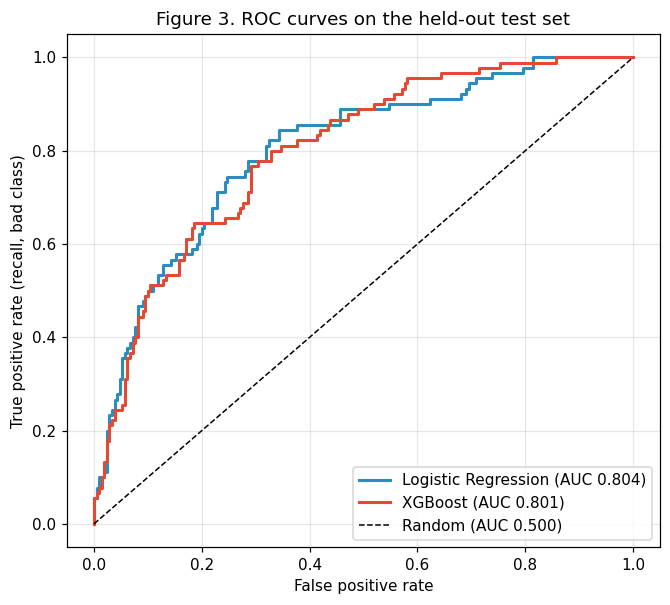

In [11]:
plt.figure(figsize=(6.2, 5.6))
for name, p, c in [('Logistic Regression', p_lr, '#2b8cbe'), ('XGBoost', p_xgb, '#e34a33')]:
    fpr, tpr, _ = roc_curve(y_te, p); plt.plot(fpr, tpr, color=c, lw=2, label=f'{name} (AUC {roc_auc_score(y_te, p):.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (AUC 0.500)')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate (recall, bad class)')
plt.title('Figure 3. ROC curves on the held-out test set'); plt.legend(loc='lower right')
plt.tight_layout(); plt.savefig('fig3_roc.png', dpi=200, bbox_inches='tight'); plt.show()

### Figure 5: confusion matrices at the 0.50 threshold

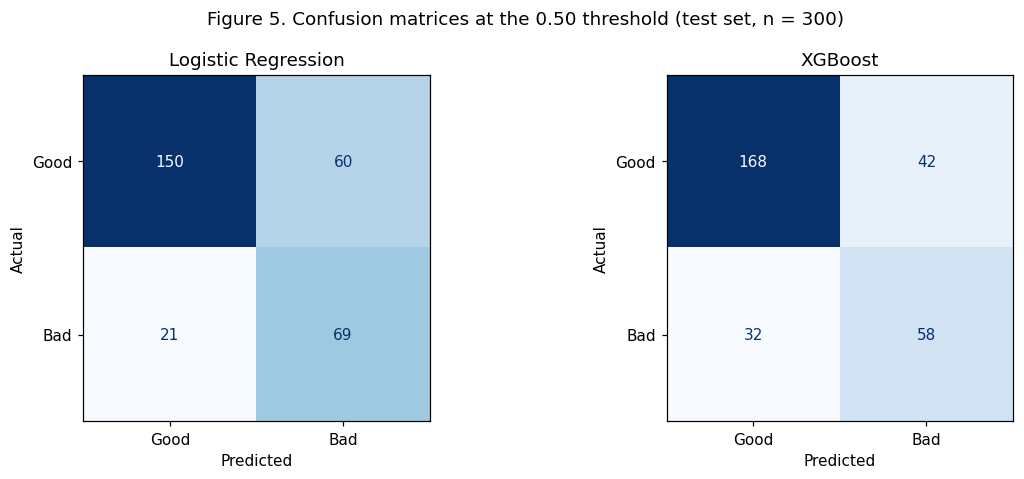

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (name, p) in zip(axes, [('Logistic Regression', p_lr), ('XGBoost', p_xgb)]):
    ConfusionMatrixDisplay(confusion_matrix(y_te, (p >= 0.5).astype(int)), display_labels=['Good', 'Bad']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(name); ax.grid(False); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
fig.suptitle('Figure 5. Confusion matrices at the 0.50 threshold (test set, n = 300)')
plt.tight_layout(); plt.savefig('fig5_confusion.png', dpi=200, bbox_inches='tight'); plt.show()

## 7. Cost-sensitive threshold analysis (Stage 7)
The German Credit cost matrix makes approving a bad applicant (FN) five times as costly as rejecting a good one (FP), so expected cost = 5 × FN + FP, evaluated at thresholds from 0.05 to 0.95.

Logistic Regression  cost at 0.50 =  165 | minimum = 146 at threshold 0.40
XGBoost              cost at 0.50 =  202 | minimum = 142 at threshold 0.15


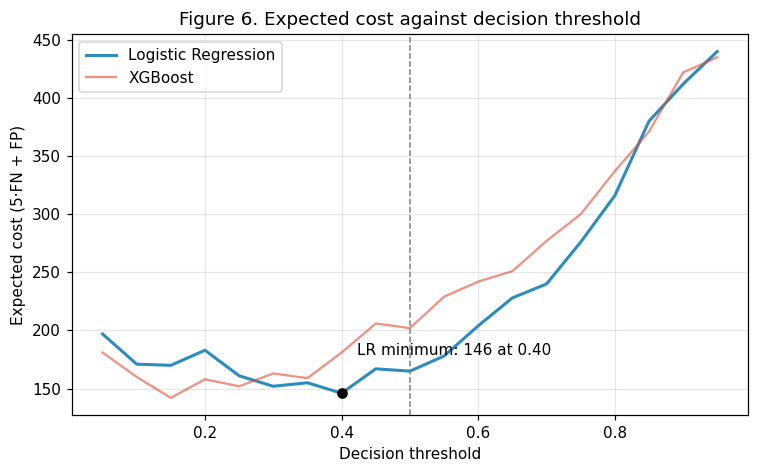

In [13]:
thr = np.round(np.arange(0.05, 0.951, 0.05), 2)   # 0.05, 0.10, ..., 0.95
def cost_curve(p):
    out = []
    for t in thr:
        tn, fp, fn, tp = confusion_matrix(y_te, (p >= t).astype(int)).ravel(); out.append(5 * fn + fp)
    return np.array(out)
cost_lr, cost_xgb = cost_curve(p_lr), cost_curve(p_xgb)
for name, c in [('Logistic Regression', cost_lr), ('XGBoost', cost_xgb)]:
    i = c.argmin(); print(f'{name:<20} cost at 0.50 = {c[thr == 0.5][0]:>4} | minimum = {c[i]} at threshold {thr[i]:.2f}')

plt.figure(figsize=(7, 4.4))
plt.plot(thr, cost_lr, color='#2b8cbe', lw=2, label='Logistic Regression')
plt.plot(thr, cost_xgb, color='#e34a33', lw=1.5, alpha=0.6, label='XGBoost')
i = cost_lr.argmin(); plt.scatter(thr[i], cost_lr[i], color='k', zorder=3)
plt.annotate(f'LR minimum: {cost_lr[i]} at {thr[i]:.2f}', (thr[i], cost_lr[i]), xytext=(10, 25), textcoords='offset points')
plt.axvline(0.5, color='grey', ls='--', lw=1); plt.xlabel('Decision threshold'); plt.ylabel('Expected cost (5·FN + FP)')
plt.title('Figure 6. Expected cost against decision threshold'); plt.legend()
plt.tight_layout(); plt.savefig('fig6_cost_threshold.png', dpi=200, bbox_inches='tight'); plt.show()

## 8. Logistic Regression coefficients and odds ratios
The interpretable benchmark explains itself: each coefficient is a global, fixed effect on the log-odds of default (standardised inputs).

In [14]:
coef = pd.DataFrame({'coefficient': lr.coef_[0], 'odds_ratio': np.exp(lr.coef_[0])}, index=feat_names)
coef['abs'] = coef.coefficient.abs()
print('Intercept:', round(lr.intercept_[0], 3))
coef.sort_values('abs', ascending=False).drop(columns='abs').head(15).round(3)

Intercept: -0.503


,coefficient,odds_ratio
cat__Attribute4_A46,1.060,2.886
cat__Attribute1_A14,-1.016,0.362
cat__Attribute3_A34,-0.829,0.437
cat__Attribute20_A202,-0.704,0.494
cat__Attribute7_A74,-0.694,0.500
cat__Attribute20_A201,0.673,1.960
cat__Attribute4_A41,-0.650,0.522
cat__Attribute4_A410,-0.649,0.523
cat__Attribute6_A61,0.633,1.884
cat__Attribute6_A64,-0.623,0.536


## 9. SHAP explanations (Stage 8) and SHAP stability across ten runs (Stage 9)
XGBoost and Logistic Regression are retrained on **ten** stratified 70/30 splits (seeds 0–9). In each run:
- test AUC of both models is recorded (Figure 4, the resampled robustness check);
- TreeSHAP values are computed for XGBoost, and mean |SHAP| is summed back to the 20 original features;
- the absolute LR coefficients are aggregated the same way (the stability benchmark).

Stability is then measured with Spearman ρ over all 45 pairs of runs. Thresholds were fixed in the proposal: ρ ≥ 0.90 means stable, 0.80–0.90 means moderate, and below 0.80 is concerning.

In [15]:
def to_original(series):
    # Sum one-hot columns back to the 20 original features
    key = lambda n: (n.split('__', 1)[1].rsplit('_', 1)[0] if n.startswith('cat__') else n.split('__', 1)[1])
    return series.groupby(key).sum().rename(index=lambda k: NAMES.get(k, k))

SEEDS = range(10)
shap_imp, lr_imp, aucs = [], [], []
for seed in SEEDS:
    a_tr, a_te, b_tr, b_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed)
    pre_s = make_preprocessor(); A = pre_s.fit_transform(a_tr); B = pre_s.transform(a_te); names = pre_s.get_feature_names_out()
    xgb_s = make_xgb(seed, (b_tr == 0).sum() / (b_tr == 1).sum()).fit(A, b_tr)
    lr_s = make_lr().fit(A, b_tr)
    aucs.append((roc_auc_score(b_te, lr_s.predict_proba(B)[:, 1]), roc_auc_score(b_te, xgb_s.predict_proba(B)[:, 1])))
    sv = shap.TreeExplainer(xgb_s).shap_values(B)
    shap_imp.append(to_original(pd.Series(np.abs(sv).mean(axis=0), index=names)))
    lr_imp.append(to_original(pd.Series(np.abs(lr_s.coef_[0]), index=names)))
    if seed == 0:
        sv0, B0, names0 = sv, B, names
    print(f'run {seed}: AUC LR {aucs[-1][0]:.3f} | XGB {aucs[-1][1]:.3f}')

run 0: AUC LR 0.805 | XGB 0.799
run 1: AUC LR 0.773 | XGB 0.764
run 2: AUC LR 0.772 | XGB 0.777
run 3: AUC LR 0.790 | XGB 0.777
run 4: AUC LR 0.804 | XGB 0.813
run 5: AUC LR 0.755 | XGB 0.753
run 6: AUC LR 0.782 | XGB 0.812
run 7: AUC LR 0.780 | XGB 0.802
run 8: AUC LR 0.733 | XGB 0.758
run 9: AUC LR 0.796 | XGB 0.799


### Figure 7: SHAP summary plot for XGBoost (seed 0)

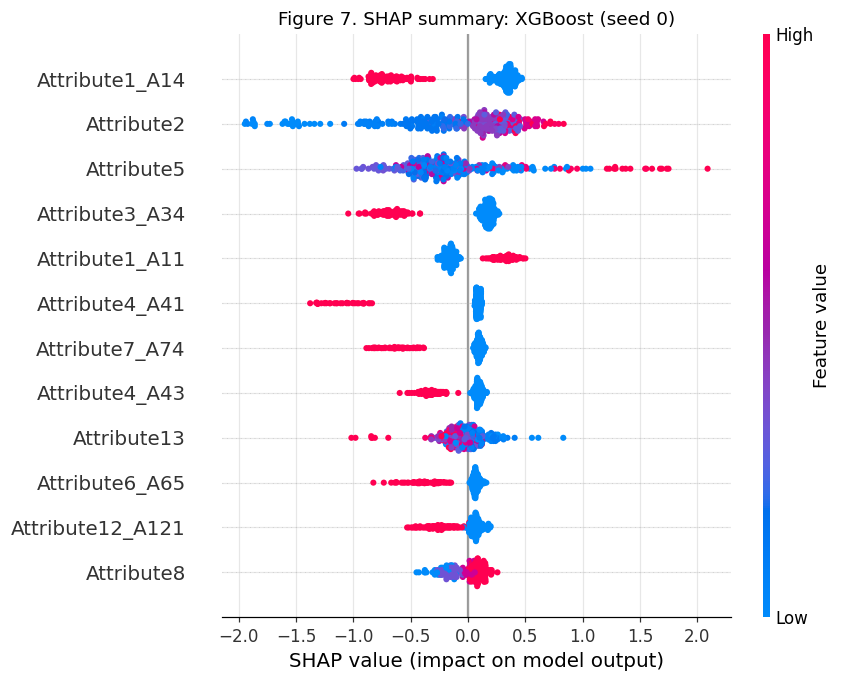

In [16]:
plt.figure()
shap.summary_plot(sv0, pd.DataFrame(B0, columns=[n.split('__', 1)[1] for n in names0]), max_display=12, show=False)
plt.title('Figure 7. SHAP summary: XGBoost (seed 0)'); plt.tight_layout()
plt.savefig('fig7_shap_summary.png', dpi=200, bbox_inches='tight'); plt.show()

### Figure 4: test ROC-AUC of both models across the ten resampled splits

LR : mean 0.779  SD 0.021
XGB: mean 0.785  SD 0.021
XGB higher in 6/10 runs | difference (XGB − LR): mean +0.006, range -0.012 to +0.030


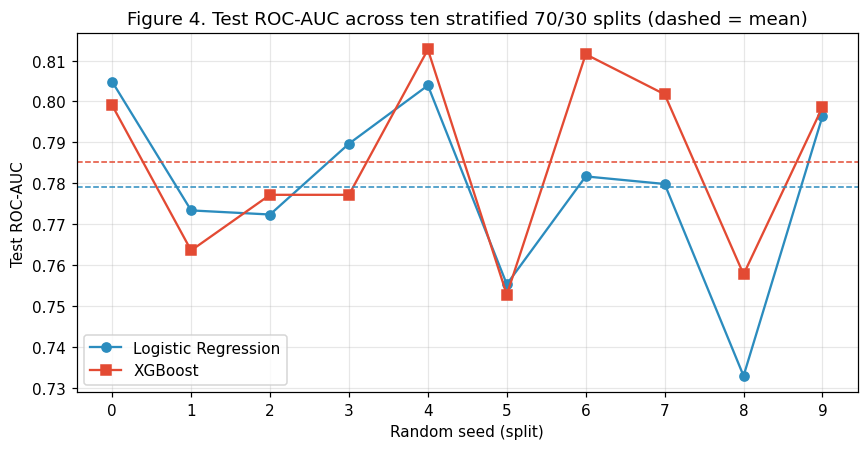

In [17]:
a = np.array(aucs)
print(f'LR : mean {a[:, 0].mean():.3f}  SD {a[:, 0].std():.3f}')
print(f'XGB: mean {a[:, 1].mean():.3f}  SD {a[:, 1].std():.3f}')
d = a[:, 1] - a[:, 0]
print(f'XGB higher in {(d > 0).sum()}/10 runs | difference (XGB − LR): mean {d.mean():+.3f}, range {d.min():+.3f} to {d.max():+.3f}')
plt.figure(figsize=(8, 4.2))
plt.plot(SEEDS, a[:, 0], 'o-', color='#2b8cbe', label='Logistic Regression'); plt.plot(SEEDS, a[:, 1], 's-', color='#e34a33', label='XGBoost')
plt.axhline(a[:, 0].mean(), color='#2b8cbe', ls='--', lw=1); plt.axhline(a[:, 1].mean(), color='#e34a33', ls='--', lw=1)
plt.xticks(list(SEEDS)); plt.xlabel('Random seed (split)'); plt.ylabel('Test ROC-AUC')
plt.title('Figure 4. Test ROC-AUC across ten stratified 70/30 splits (dashed = mean)'); plt.legend()
plt.tight_layout(); plt.savefig('fig4_auc_seeds.png', dpi=200, bbox_inches='tight'); plt.show()

### Tables 6 and 7: SHAP rank stability

In [18]:
S = pd.DataFrame(shap_imp).T; L = pd.DataFrame(lr_imp).T       # features x runs
R = S.rank(ascending=False)
pairs = list(combinations(S.columns, 2))
top10 = S.mean(axis=1).sort_values(ascending=False).index[:10]
rho_all = [spearmanr(S[i], S[j])[0] for i, j in pairs]
rho_top = [spearmanr(S.loc[top10, i], S.loc[top10, j])[0] for i, j in pairs]
rho_lr = [spearmanr(L[i], L[j])[0] for i, j in pairs]

def verdict(m): return 'stable (≥ 0.90)' if m >= 0.90 else ('moderate (0.80–0.90)' if m >= 0.80 else 'concerning (< 0.80)')
table7 = pd.DataFrame({'Mean rho': [np.mean(r) for r in (rho_all, rho_top, rho_lr)],
                       'SD': [np.std(r) for r in (rho_all, rho_top, rho_lr)],
                       'Min rho': [np.min(r) for r in (rho_all, rho_top, rho_lr)],
                       'Max rho': [np.max(r) for r in (rho_all, rho_top, rho_lr)]},
                      index=['XGBoost SHAP, all 20 features', 'XGBoost SHAP, top 10 features', 'LR |coefficients|, all 20 features'])
table7['Verdict'] = table7['Mean rho'].apply(verdict)
print('Table 7. Stability across 45 pairs of runs'); display(table7.round(3))

table6 = pd.DataFrame({'Mean rank': R.mean(axis=1), 'Rank SD': R.std(axis=1), 'Best rank': R.min(axis=1),
                       'Worst rank': R.max(axis=1), 'Runs in top 5': (R <= 5).sum(axis=1)}).sort_values('Mean rank')
print('Table 6. SHAP importance rank across ten runs (1 = most important)'); table6.round(2)

Table 7. Stability across 45 pairs of runs


,Mean rho,SD,Min rho,Max rho,Verdict
"XGBoost SHAP, all 20 features",0.913,0.024,0.853,0.964,stable (≥ 0.90)
"XGBoost SHAP, top 10 features",0.852,0.077,0.624,0.952,moderate (0.80–0.90)
"LR |coefficients|, all 20 features",0.929,0.030,0.841,0.970,stable (≥ 0.90)


Table 6. SHAP importance rank across ten runs (1 = most important)


,Mean rank,Rank SD,Best rank,Worst rank,Runs in top 5
checking_account,1.0,0.00,1.0,1.0,10
purpose,2.1,0.32,2.0,3.0,10
credit_history,4.1,1.79,2.0,8.0,8
duration_months,4.4,1.43,3.0,7.0,8
credit_amount,4.5,0.71,3.0,5.0,10
employment_since,6.0,1.25,4.0,8.0,2
savings,6.2,1.23,4.0,7.0,2
property,9.1,0.99,8.0,11.0,0
personal_status_sex,9.6,2.50,6.0,14.0,0
age_years,10.2,1.87,8.0,13.0,0


### Figure 8: range of SHAP ranks for the twelve leading features

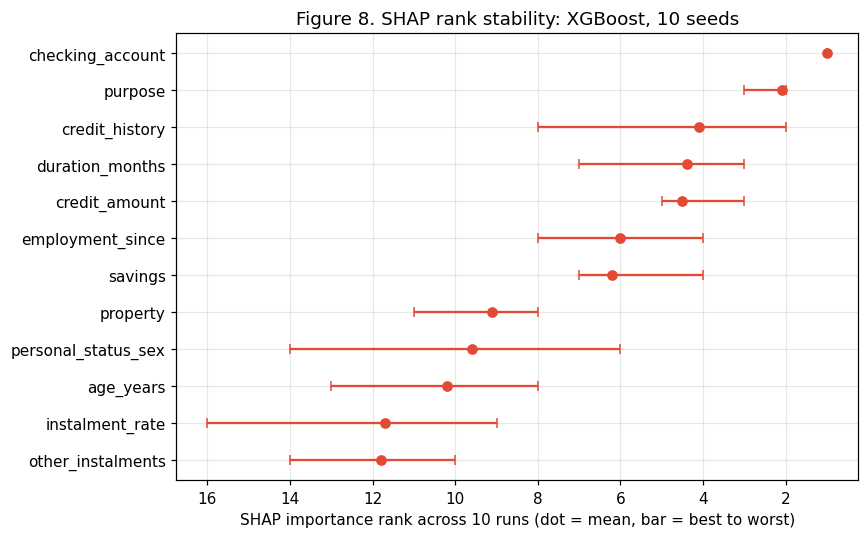

In [19]:
s = table6.iloc[:12][::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(s['Mean rank'], s.index, xerr=[s['Mean rank'] - s['Best rank'], s['Worst rank'] - s['Mean rank']],
            fmt='o', capsize=3, color='#e34a33')
ax.set_xlabel('SHAP importance rank across 10 runs (dot = mean, bar = best to worst)'); ax.invert_xaxis()
ax.set_title('Figure 8. SHAP rank stability: XGBoost, 10 seeds')
plt.tight_layout(); plt.savefig('fig8_shap_stability.png', dpi=200, bbox_inches='tight'); plt.show()

### Agreement between SHAP (XGBoost) and Logistic Regression importance (RO4)

In [20]:
rho_cross = spearmanr(S.mean(axis=1), L.mean(axis=1))[0]
top5_shap = set(S.mean(axis=1).nlargest(5).index); top5_lr = set(L.mean(axis=1).nlargest(5).index)
print(f'Spearman rho between average SHAP and average |LR coefficient| rankings: {rho_cross:.3f}')
print('In both top fives :', sorted(top5_shap & top5_lr))
print('SHAP top five only:', sorted(top5_shap - top5_lr))
print('LR top five only  :', sorted(top5_lr - top5_shap))
pd.DataFrame({'SHAP mean |value|': S.mean(axis=1), 'SHAP rank': S.mean(axis=1).rank(ascending=False),
              'LR mean |coef|': L.mean(axis=1), 'LR rank': L.mean(axis=1).rank(ascending=False)}).sort_values('SHAP rank').round(3)

Spearman rho between average SHAP and average |LR coefficient| rankings: 0.574
In both top fives : ['checking_account', 'credit_history', 'purpose']
SHAP top five only: ['credit_amount', 'duration_months']
LR top five only  : ['foreign_worker', 'savings']


,SHAP mean |value|,SHAP rank,LR mean |coef|,LR rank
checking_account,0.866,1.0,2.077,3.0
purpose,0.549,2.0,4.505,1.0
credit_history,0.420,3.0,2.264,2.0
credit_amount,0.404,4.0,0.392,13.0
duration_months,0.396,5.0,0.310,15.0
savings,0.353,6.0,1.746,4.0
employment_since,0.345,7.0,1.381,6.0
property,0.218,8.0,0.916,9.0
personal_status_sex,0.202,9.0,1.052,8.0
age_years,0.196,10.0,0.132,18.0


## 10. Summary of results by research objective
The cell below prints the key figures used in Table 8 of the report.

In [21]:
print('RO1  Primary split (seed 42): AUC LR {:.3f} vs XGB {:.3f}; recall (bad) LR {:.3f} vs XGB {:.3f}; '
      'expected cost LR {:.0f} vs XGB {:.0f}; LR cost-minimising threshold {:.2f}'.format(
      perf.loc['Logistic Regression', 'ROC-AUC'], perf.loc['XGBoost', 'ROC-AUC'], perf.loc['Logistic Regression', 'Recall (bad)'],
      perf.loc['XGBoost', 'Recall (bad)'], perf.loc['Logistic Regression', 'Expected cost (5·FN+FP)'],
      perf.loc['XGBoost', 'Expected cost (5·FN+FP)'], thr[cost_lr.argmin()]))
print('RO1  Ten splits: mean AUC LR {:.3f} vs XGB {:.3f} (SD {:.3f}/{:.3f}); XGB higher in {}/10'.format(
      a[:, 0].mean(), a[:, 1].mean(), a[:, 0].std(), a[:, 1].std(), (a[:, 1] > a[:, 0]).sum()))
print('RO2  Leading SHAP features:', ', '.join(table6.index[:5]))
print('RO3  SHAP rho all 20 = {:.3f} ({}); top 10 = {:.3f}; LR coefficients = {:.3f}'.format(
      np.mean(rho_all), verdict(np.mean(rho_all)), np.mean(rho_top), np.mean(rho_lr)))
print('RO4  SHAP vs LR ranking agreement rho = {:.3f}'.format(rho_cross))

RO1  Primary split (seed 42): AUC LR 0.804 vs XGB 0.801; recall (bad) LR 0.767 vs XGB 0.644; expected cost LR 165 vs XGB 202; LR cost-minimising threshold 0.40
RO1  Ten splits: mean AUC LR 0.779 vs XGB 0.785 (SD 0.021/0.021); XGB higher in 6/10
RO2  Leading SHAP features: checking_account, purpose, credit_history, duration_months, credit_amount
RO3  SHAP rho all 20 = 0.913 (stable (≥ 0.90)); top 10 = 0.852; LR coefficients = 0.929
RO4  SHAP vs LR ranking agreement rho = 0.574


## References
- Chen, T. and Guestrin, C. (2016) 'XGBoost: A scalable tree boosting system', *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, pp. 785–794.
- Hofmann, H. (1994) *Statlog (German Credit Data)* [Dataset]. UCI Machine Learning Repository. Available at: https://doi.org/10.24432/C5NC77 (Accessed: 4 November 2026).
- Lundberg, S.M. et al. (2020) 'From local explanations to global understanding with explainable AI for trees', *Nature Machine Intelligence*, 2(1), pp. 56–67.
- Pedregosa, F. et al. (2011) 'Scikit-learn: Machine learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825–2830.